<a href="https://colab.research.google.com/github/Azizkhan-23/Supervised-Classification-Regression-Modeling-Tuning/blob/main/Feature_Engineering_%26_Preprocessing_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("customer-churn-training.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Saving customer-churn-training.csv to customer-churn-training.csv
Dataset shape: (12, 7)

Column names:
['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


In [ ]:

from sklearn.model_selection import train_test_split

# Find the target column
target_candidates = [
    col for col in df.columns
    if col.strip().lower() in [
        "churn", "churned", "exited", "customer_status"
    ]
]

if not target_candidates:
    raise ValueError(
        "Target column not found. Check df.columns.tolist() "
        "and set the correct target column manually."
    )

target = target_candidates[0]
print("Target column:", target)

# Remove rows where the target is missing
data = df.dropna(subset=[target]).copy()

X = data.drop(columns=[target])
y = data[target]

# Split before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Target column: churned
Training data: (9, 6)
Testing data: (3, 6)


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Identify column types using training data only
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Complete ML pipeline
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Fit only on training data
model.fit(X_train, y_train)

print("Preprocessing pipeline completed!")


Preprocessing pipeline completed!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3


Confusion Matrix:
[[2 0]
 [0 1]]


,tenure_months,support_tickets,monthly_spend_inr,last_login_days
tenure_months,1.00,-0.93,0.91,-0.87
support_tickets,-0.93,1.00,-0.84,0.94
monthly_spend_inr,0.91,-0.84,1.00,-0.90
last_login_days,-0.87,0.94,-0.90,1.00


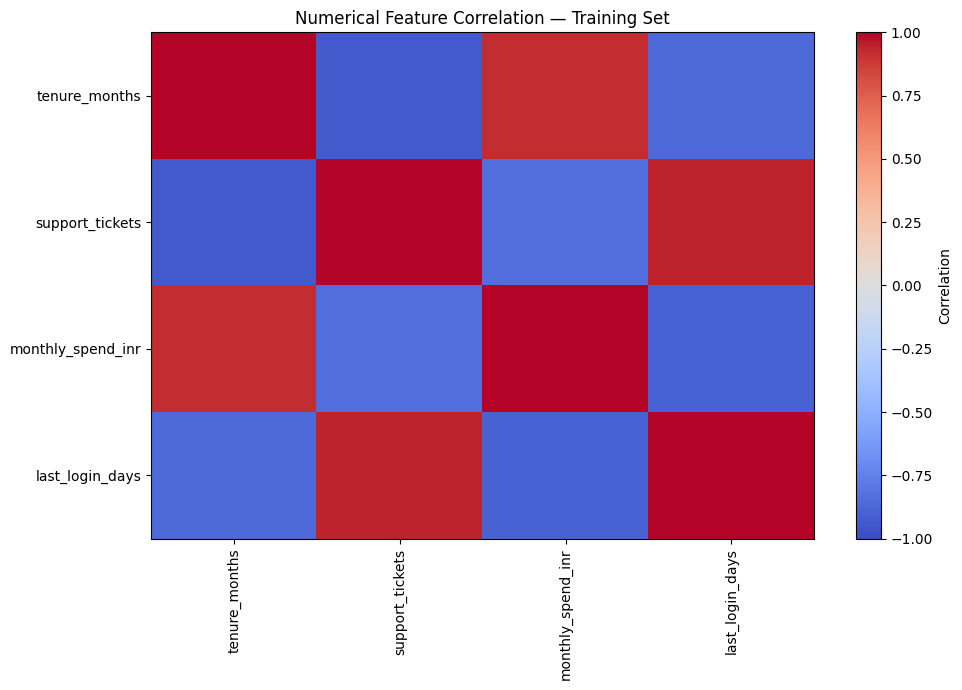

In [ ]:

import matplotlib.pyplot as plt

correlation = X_train.select_dtypes(
    include=["number"]
).corr()

display(correlation.round(2))

plt.figure(figsize=(10, 7))
plt.imshow(correlation, aspect="auto", cmap="coolwarm",
           vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)
plt.title("Numerical Feature Correlation — Training Set")
plt.tight_layout()
plt.show()


Top 15 Important Features:


,Feature,Importance
2,num__monthly_spend_inr,2.352833e-01
3,num__last_login_days,1.957618e-01
13,cat__plan_type_Basic,1.677816e-01
1,num__support_tickets,1.479355e-01
0,num__tenure_months,1.376471e-01
14,cat__plan_type_Pro,3.277206e-02
15,cat__plan_type_Standard,3.021164e-02
10,cat__customer_id_C008,1.893903e-02
12,cat__customer_id_C011,1.838235e-02
9,cat__customer_id_C006,1.088889e-02


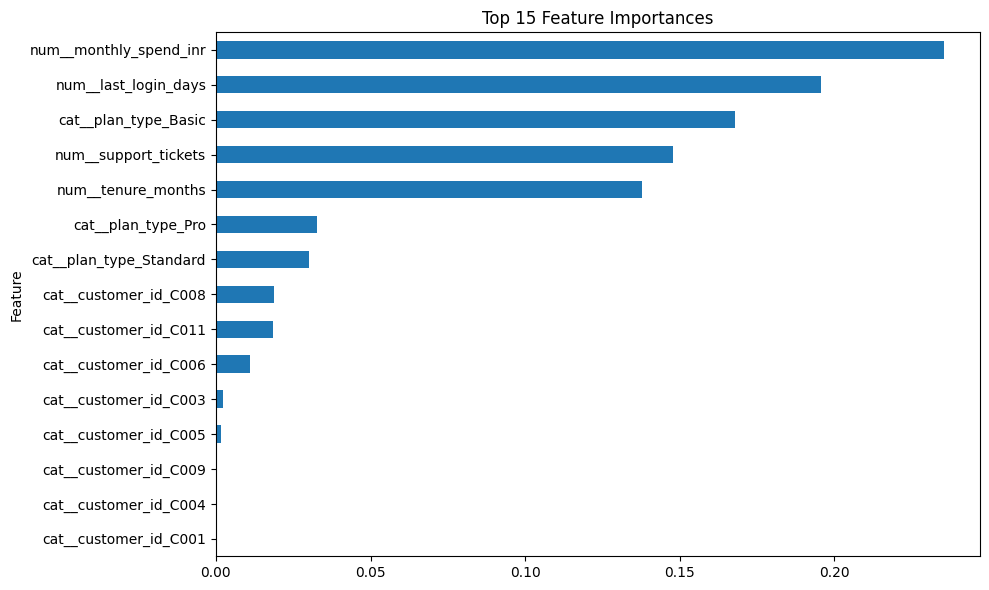

In [ ]:

feature_names = (
    model.named_steps["preprocessing"]
    .get_feature_names_out()
)

importances = (
    model.named_steps["classifier"].feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("Top 15 Important Features:")
display(importance_df.head(15))

importance_df.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()




### Feature Engineering & Preprocessing Pipeline — Conclusion

A leak-free machine-learning pipeline was developed using Scikit-learn. The dataset was split into training and testing sets before fitting any preprocessing transformations.

Numerical features were processed using median imputation and standard scaling. Categorical features were processed using mode imputation and One-Hot Encoding. A ColumnTransformer combined the transformations, and a Random Forest classifier was trained and evaluated on the test set.

Correlation analysis was performed on numerical training features, and tree-based feature importance was used to identify influential features.

The pipeline reduces data leakage risks and handles missing values and previously unseen categorical values. Model performance should be assessed using accuracy, precision, recall, F1-score, and the business context of customer churn.